# Demo 11 - Do Perceptron ao MLP: o problema do XOR e o backpropagation

### MBA em AI Engineering & Multi Agents - Machine Learning Foundations & Classic Models.

### Prof. Dr. Ahirton Lopes (profahirton.lopes@fiap.com.br)

## Objetivo da demo

Na Demo 10 vimos **como** um modelo aprende (descida do gradiente). Agora vamos ver **por que** precisamos de redes com mais de uma camada, revivendo um dos episódios mais famosos da história da IA:

> Em 1969, Minsky e Papert mostraram que um perceptron de uma camada **não consegue** aprender nem uma função lógica simples, o XOR. O entusiasmo com redes neurais esfriou por mais de uma década. A saída veio com as **camadas ocultas** treinadas por **backpropagation** (Rumelhart, Hinton e Williams, 1986).

| Seção | Conteúdo |
| --- | --- |
| 1 | O perceptron de Rosenblatt, implementado do zero |
| 2 | O perceptron aprende AND, mas falha no XOR |
| 3 | Um MLP do zero em NumPy, com backpropagation comentado passo a passo |
| 4 | Do brinquedo ao dado realista: regressão logística x MLP no `scikit-learn` |
| 5 | O mesmo MLP em Keras: o formato que vocês vão usar na próxima disciplina |
| 6 | Conclusão |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

def plota_fronteira(ax, prever, X, y, titulo):
    """Pinta a região de decisão de um classificador em 2D."""
    margem = 0.5
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - margem, X[:, 0].max() + margem, 300),
                         np.linspace(X[:, 1].min() - margem, X[:, 1].max() + margem, 300))
    zz = prever(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=['#f4c7c3', '#c6dbef'], alpha=0.8)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm_r', edgecolor='k', s=60)
    ax.set_title(titulo)

## 1. O perceptron de Rosenblatt

O perceptron (Frank Rosenblatt, 1958) é o neurônio de McCulloch e Pitts que vimos nos slides, **com uma regra de aprendizado**:

1. calcula a soma ponderada $z = w_1 x_1 + w_2 x_2 + b$;
2. aplica um **degrau**: se $z \geq 0$, responde 1; senão, 0;
3. quando erra, ajusta os pesos na direção do acerto: $w \leftarrow w + \eta\,(y - \hat{y})\,x$.

Repare que é a mesma ideia da descida do gradiente: corrigir os parâmetros proporcionalmente ao erro.

In [2]:
class Perceptron:
    def __init__(self, taxa_aprendizado=0.1, epocas=50):
        self.taxa = taxa_aprendizado
        self.epocas = epocas

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        self.acuracia_por_epoca = []
        for _ in range(self.epocas):
            for xi, yi in zip(X, y):
                erro = yi - self.predict(xi.reshape(1, -1))[0]
                self.w += self.taxa * erro * xi      # regra de Rosenblatt
                self.b += self.taxa * erro
            self.acuracia_por_epoca.append(np.mean(self.predict(X) == y))
        return self

    def predict(self, X):
        return (X @ self.w + self.b >= 0).astype(int)

## 2. AND funciona, XOR não

As duas tabelas-verdade:

| $x_1$ | $x_2$ | AND | XOR |
| --- | --- | --- | --- |
| 0 | 0 | 0 | 0 |
| 0 | 1 | 0 | **1** |
| 1 | 0 | 0 | **1** |
| 1 | 1 | 1 | 0 |

O XOR responde 1 quando **exatamente uma** entrada está ligada. Parece inofensivo.

AND -> previsões: [0 0 0 1] | esperado: [0 0 0 1] | acurácia: 100%
XOR -> previsões: [1 1 0 0] | esperado: [0 1 1 0] | acurácia: 50%

Melhor acurácia do perceptron no XOR em 50 épocas: 50%


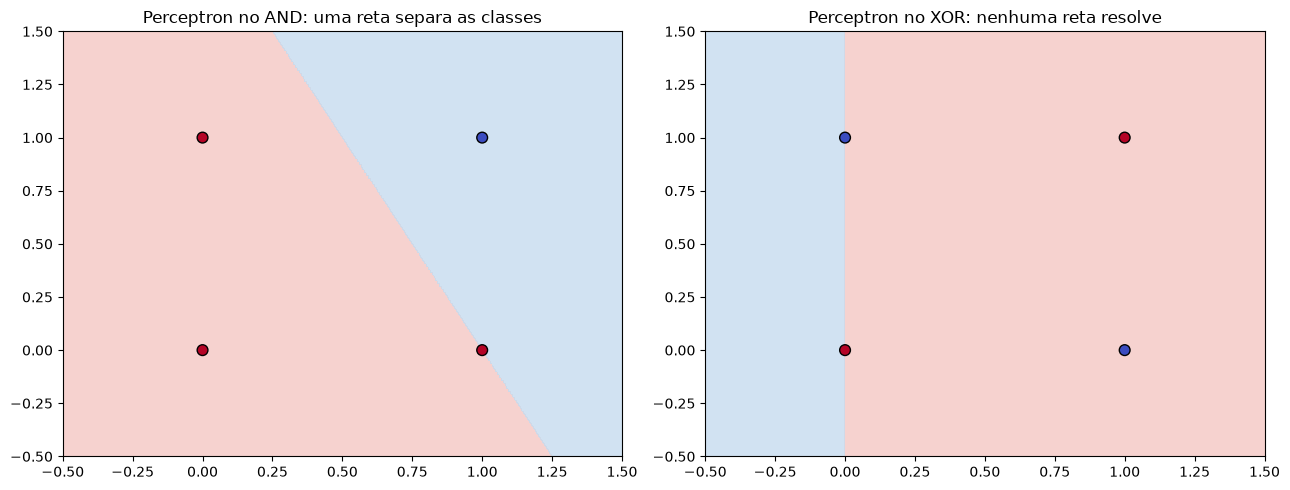

In [3]:
X_logico = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_and = np.array([0, 0, 0, 1])
y_xor = np.array([0, 1, 1, 0])

p_and = Perceptron().fit(X_logico, y_and)
p_xor = Perceptron().fit(X_logico, y_xor)

print('AND -> previsões:', p_and.predict(X_logico), '| esperado:', y_and,
      f'| acurácia: {np.mean(p_and.predict(X_logico) == y_and):.0%}')
print('XOR -> previsões:', p_xor.predict(X_logico), '| esperado:', y_xor,
      f'| acurácia: {np.mean(p_xor.predict(X_logico) == y_xor):.0%}')
print('\nMelhor acurácia do perceptron no XOR em 50 épocas:', f'{max(p_xor.acuracia_por_epoca):.0%}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plota_fronteira(axes[0], p_and.predict, X_logico, y_and, 'Perceptron no AND: uma reta separa as classes')
plota_fronteira(axes[1], p_xor.predict, X_logico, y_xor, 'Perceptron no XOR: nenhuma reta resolve')
plt.tight_layout()
plt.show()

**Por que o XOR é impossível para o perceptron?** Olhe o gráfico da direita: os pontos azuis (classe 1) estão em cantos **opostos**, e os vermelhos (classe 0) também. Não existe **uma única reta** que deixe os dois azuis de um lado e os dois vermelhos do outro. O perceptron só sabe desenhar retas, então nunca passa de 3 de 4 acertos (aqui ficou em 2 de 4, o mesmo que chutar).

Dizemos que o XOR **não é linearmente separável**. E problemas reais (fraude, churn, imagens, texto) quase nunca são.

## 3. A solução: uma camada oculta (MLP) treinada por backpropagation

A ideia é colocar neurônios **entre** a entrada e a saída. Cada neurônio oculto desenha a sua própria reta, e a saída **combina** essas retas em uma fronteira curva.

Vamos construir o menor MLP que resolve o XOR, **do zero, em NumPy**:

- 2 entradas -> **4 neurônios ocultos** (ativação tanh) -> 1 saída (sigmoid, que devolve uma probabilidade);
- perda: **entropia cruzada binária** (a mesma da regressão logística);
- treino: descida do gradiente, com o gradiente calculado por **backpropagation**.

### Backpropagation em uma frase

> O erro é medido na saída e **distribuído de trás para frente**, camada por camada, usando a regra da cadeia do cálculo: cada peso recebe a sua "parcela de culpa" pelo erro final.

O código abaixo tem exatamente três blocos: **forward** (prever), **backward** (distribuir a culpa) e **atualização** (descer o gradiente).

In [4]:
rng = np.random.default_rng(3)

# Pesos iniciais aleatórios e pequenos
W1 = rng.normal(0, 1, size=(2, 4)); b1 = np.zeros(4)   # entrada -> oculta
W2 = rng.normal(0, 1, size=(4, 1)); b2 = np.zeros(1)   # oculta  -> saída

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

X, y = X_logico, y_xor.reshape(-1, 1)
taxa_aprendizado = 0.5
historico_perda = []

for epoca in range(3000):
    # ---------- FORWARD: a informação vai da entrada para a saída ----------
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)                 # camada oculta
    z2 = a1 @ W2 + b2
    y_hat = sigmoid(z2)              # probabilidade de ser classe 1

    perda = -np.mean(y * np.log(y_hat + 1e-9) + (1 - y) * np.log(1 - y_hat + 1e-9))
    historico_perda.append(perda)

    # ---------- BACKWARD: o erro volta da saída para a entrada ----------
    dz2 = (y_hat - y) / len(X)                 # culpa da saída (sigmoid + entropia cruzada)
    dW2 = a1.T @ dz2                           # culpa de cada peso oculta -> saída
    db2 = dz2.sum(axis=0)
    da1 = dz2 @ W2.T                           # a culpa "volta" para a camada oculta...
    dz1 = da1 * (1 - a1 ** 2)                  # ...passando pela derivada da tanh (regra da cadeia)
    dW1 = X.T @ dz1                            # culpa de cada peso entrada -> oculta
    db1 = dz1.sum(axis=0)

    # ---------- ATUALIZAÇÃO: descida do gradiente (Demo 10) ----------
    W1 -= taxa_aprendizado * dW1; b1 -= taxa_aprendizado * db1
    W2 -= taxa_aprendizado * dW2; b2 -= taxa_aprendizado * db2

    if epoca in [0, 100, 500, 1000, 2999]:
        print(f'Época {epoca:4d}: perda = {perda:.4f}')

def mlp_predict(X_novo):
    return (sigmoid(np.tanh(X_novo @ W1 + b1) @ W2 + b2) >= 0.5).astype(int).ravel()

print('\nProbabilidades finais:', np.round(y_hat.ravel(), 3))
print('Previsões do MLP     :', mlp_predict(X_logico), '| esperado:', y_xor)

Época    0: perda = 1.3850
Época  100: perda = 0.0628
Época  500: perda = 0.0100
Época 1000: perda = 0.0048
Época 2999: perda = 0.0015

Probabilidades finais: [0.    0.998 0.998 0.002]
Previsões do MLP     : [0 1 1 0] | esperado: [0 1 1 0]


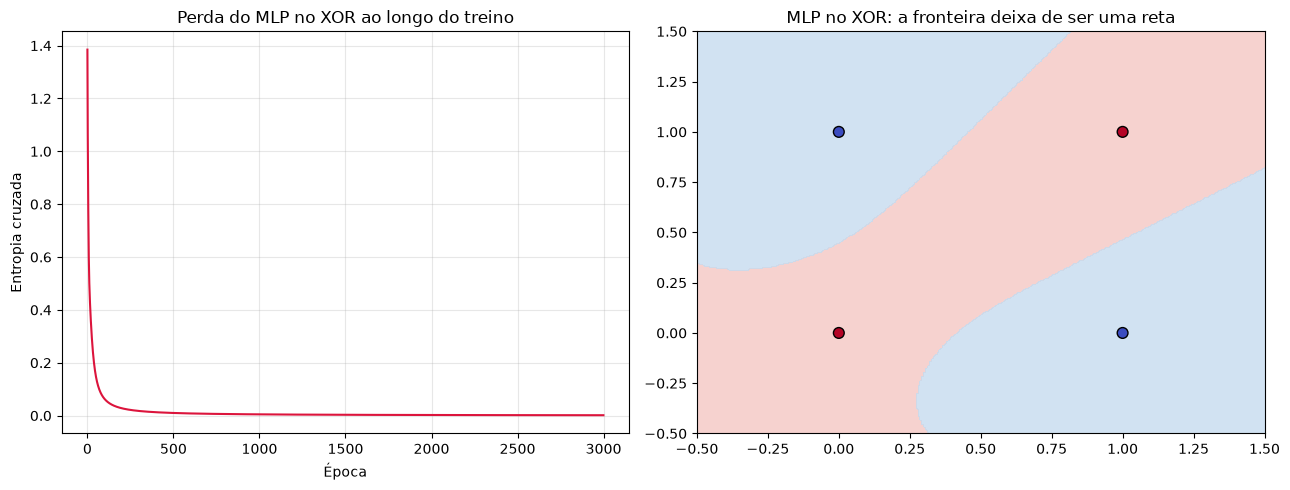

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(historico_perda, color='crimson')
axes[0].set_title('Perda do MLP no XOR ao longo do treino')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Entropia cruzada')
axes[0].grid(alpha=0.3)

plota_fronteira(axes[1], mlp_predict, X_logico, y_xor, 'MLP no XOR: a fronteira deixa de ser uma reta')
plt.tight_layout()
plt.show()

Com **uma camada oculta de 4 neurônios**, o problema que travou a área por anos é resolvido em menos de um segundo. Repare na fronteira da direita: ela não é mais uma reta, é uma **faixa**, construída pela combinação das retas de cada neurônio oculto.

Duas observações honestas sobre o que acabamos de fazer:

- escrevemos as derivadas do backward **à mão**. Com 2 camadas dá para fazer; com 100 camadas, não. Bibliotecas como **TensorFlow/Keras** e **PyTorch** fazem isso automaticamente (*autograd*). Os detalhes matemáticos do backpropagation são tema da próxima disciplina;
- a inicialização aleatória importa: com outra semente ou com menos neurônios ocultos, a rede pode empacar em um mínimo ruim. É por isso que, na prática, usamos redes um pouco maiores do que o mínimo teórico.

## 4. Do brinquedo ao dado realista: regressão logística x MLP

O XOR tem 4 pontos. Vamos para um conjunto com **1.000 pontos com ruído**, em formato de duas luas entrelaçadas (`make_moons`), que é a versão "realista" do mesmo desafio: as classes não se separam com uma reta.

Vamos comparar dois modelos do `scikit-learn`:

- **Regressão logística** (Aula 1): um modelo linear, ou seja, essencialmente um único neurônio com sigmoid;
- **MLPClassifier**: a mesma ideia da seção 3, com duas camadas ocultas e a ReLU da Demo 10.

Regressão logística -> acurácia no teste: 0.893
MLP (16, 16)        -> acurácia no teste: 0.980
Parâmetros treináveis do MLP: 337


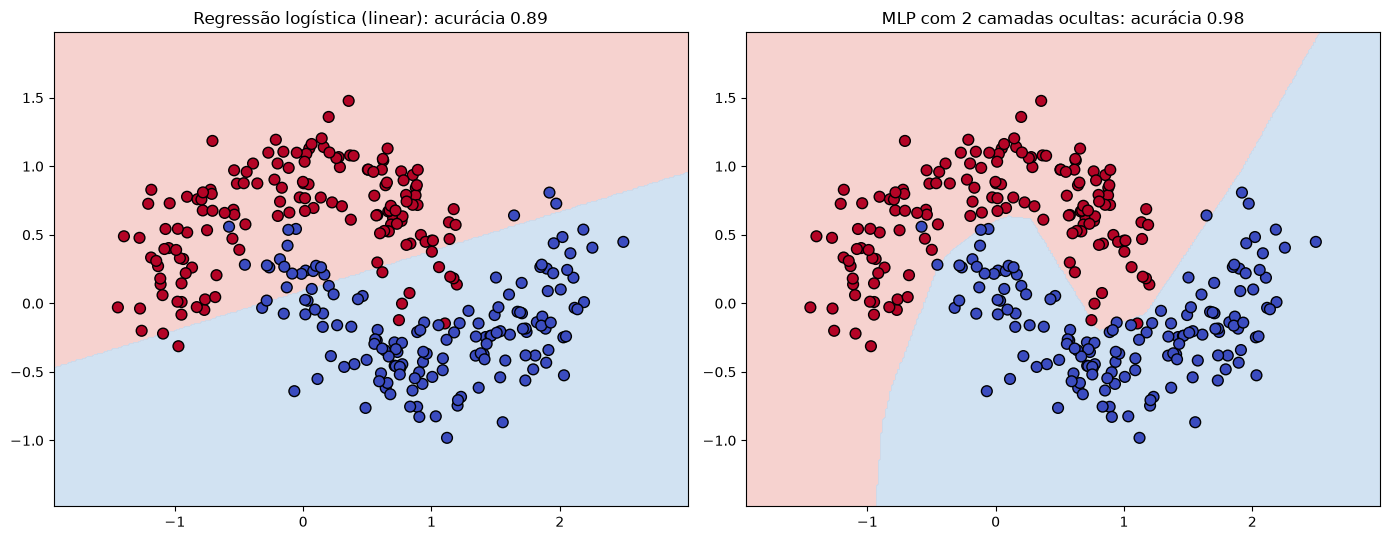

In [6]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

X_luas, y_luas = make_moons(n_samples=1000, noise=0.2, random_state=42)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X_luas, y_luas, test_size=0.3, random_state=42, stratify=y_luas)

logistica = LogisticRegression().fit(X_treino, y_treino)
mlp = MLPClassifier(hidden_layer_sizes=(16, 16), activation='relu',
                    max_iter=2000, random_state=42).fit(X_treino, y_treino)

acc_log = accuracy_score(y_teste, logistica.predict(X_teste))
acc_mlp = accuracy_score(y_teste, mlp.predict(X_teste))
print(f'Regressão logística -> acurácia no teste: {acc_log:.3f}')
print(f'MLP (16, 16)        -> acurácia no teste: {acc_mlp:.3f}')
print(f'Parâmetros treináveis do MLP: {sum(c.size for c in mlp.coefs_) + sum(c.size for c in mlp.intercepts_)}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plota_fronteira(axes[0], logistica.predict, X_teste, y_teste,
                f'Regressão logística (linear): acurácia {acc_log:.2f}')
plota_fronteira(axes[1], mlp.predict, X_teste, y_teste,
                f'MLP com 2 camadas ocultas: acurácia {acc_mlp:.2f}')
plt.tight_layout()
plt.show()

A regressão logística faz o melhor que uma reta consegue; o MLP **dobra** a fronteira para acompanhar o formato das luas.

Vale fazer um exercício mental: e se eu criasse manualmente variáveis novas para a regressão logística, como $x_1^2$, $x_1 \cdot x_2$, $\sin(x_1)$? Ela também passaria a desenhar curvas. Essa é a diferença central entre os dois mundos:

| Machine Learning clássico | Redes neurais |
| --- | --- |
| **Você** cria as variáveis certas (*feature engineering*) | A rede **aprende** as representações nas camadas ocultas |
| Funciona muito bem quando o conhecimento do domínio é bom | Brilha quando é difícil dizer quais variáveis importam (pixels, palavras, áudio) |

Esse é o argumento do slide **Machine vs. Deep Learning**, agora visto em código.

## 5. O mesmo MLP em Keras

Na próxima disciplina (*Deep Learning and Modern Neural Architectures*) vocês vão construir redes com bibliotecas de deep learning. Para que o formato não seja novidade, aqui está **o mesmo MLP da seção 4** em Keras. Repare como cada linha corresponde a um conceito que já vimos:

In [7]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'   # silencia avisos de hardware do TensorFlow

import tensorflow as tf
from tensorflow import keras

keras.utils.set_random_seed(42)

modelo = keras.Sequential([
    keras.Input(shape=(2,)),                         # camada de entrada: 2 variáveis
    keras.layers.Dense(16, activation='relu'),       # camada oculta 1 (ReLU, Demo 10)
    keras.layers.Dense(16, activation='relu'),       # camada oculta 2
    keras.layers.Dense(1, activation='sigmoid'),     # saída: probabilidade da classe 1
])

modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01),   # descida do gradiente "turbinada"
               loss='binary_crossentropy',                            # a mesma perda da seção 3
               metrics=['accuracy'])

modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

Keras MLP -> acurácia no teste: 0.970


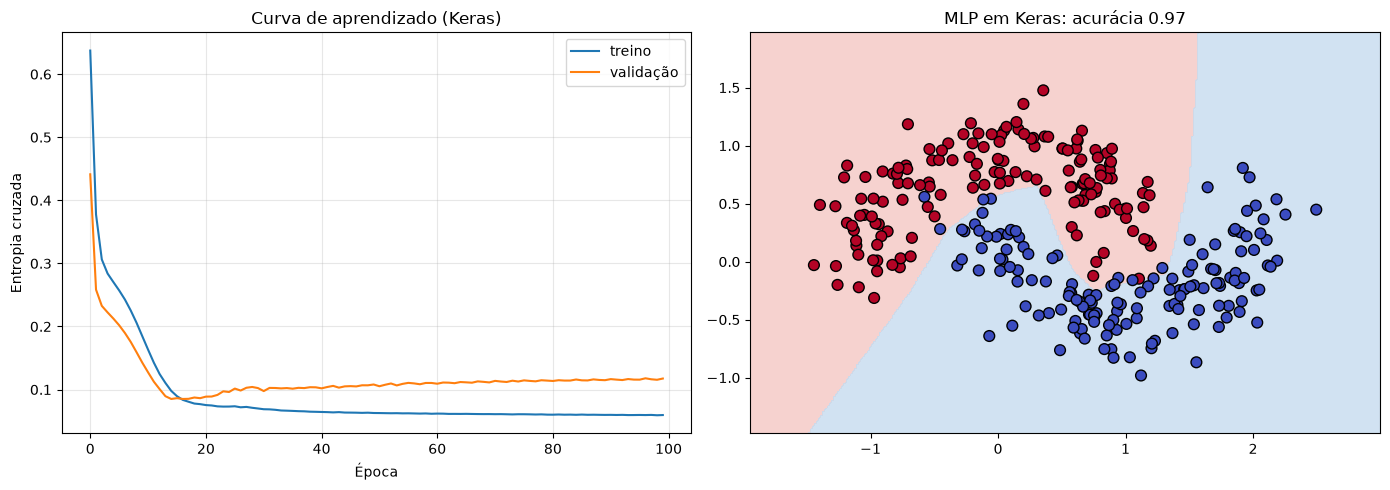

In [8]:
historico = modelo.fit(X_treino, y_treino, validation_split=0.2,
                       epochs=100, batch_size=32, verbose=0)

perda_teste, acc_keras = modelo.evaluate(X_teste, y_teste, verbose=0)
print(f'Keras MLP -> acurácia no teste: {acc_keras:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(historico.history['loss'], label='treino')
axes[0].plot(historico.history['val_loss'], label='validação')
axes[0].set_title('Curva de aprendizado (Keras)')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Entropia cruzada')
axes[0].legend()
axes[0].grid(alpha=0.3)

prever_keras = lambda X_novo: (modelo.predict(X_novo, verbose=0) >= 0.5).astype(int).ravel()
plota_fronteira(axes[1], prever_keras, X_teste, y_teste, f'MLP em Keras: acurácia {acc_keras:.2f}')
plt.tight_layout()
plt.show()

**Como ler a curva de aprendizado:** nas primeiras ~20 épocas, treino e validação caem juntas: a rede está aprendendo padrões que generalizam. Depois disso, repare que a perda de **treino continua caindo** enquanto a de **validação para de cair e sobe devagar**. É o **overfitting** da Aula 1 aparecendo, agora em forma de gráfico: a rede começa a decorar o ruído do treino.

Na prática, o remédio mais simples é parar o treino no ponto em que a validação foi melhor (*early stopping*), que é justamente o `early_stopping=True` que usaremos no MLP da Demo 12. Esse e outros regularizadores (*dropout*, *weight decay*) são aprofundados na próxima disciplina.

## 6. Conclusão

- Um único neurônio (perceptron, regressão logística) só desenha **retas**. Problemas não linearmente separáveis, como o XOR, exigem **camadas ocultas**.
- O **MLP** combina várias retas em fronteiras curvas, e é treinado com a descida do gradiente da Demo 10.
- O **backpropagation** é o algoritmo que calcula, de trás para frente, quanto cada peso contribuiu para o erro. Fizemos à mão para uma rede pequena; frameworks como Keras e PyTorch fazem automaticamente.
- A grande virada do deep learning é trocar **feature engineering manual** por **representações aprendidas**.

**Próximo passo (Demo 12):** levar MLP e modelos clássicos para um problema de negócio real, com dados tabulares, e ver quem ganha. O resultado pode surpreender.